# データサイエンス実践A 第２回課題：模範解答
### 新潟大学 創生学部（2026年度）

- 問1〜3 は、新潟県のデータで作った例。課題では、自分で選んだ自治体のデータを探して使う（問2・3 は出身の県か市町村）
- グラフは `plt.savefig` で透明化（`transparent=True`）して png に保存し、パワーポイントの１ページに張る
- 使うファイル（この notebook と同じフォルダに置く）
  - `DSA2026_kadai2_模範解答.xlsx`：配布した `DSA2026_kadai2.xlsx` の空のシート（`問1_円グラフ`・`問2_両y軸`）に、下の URL のデータを書き写したもの。`問4_身長`・`問4_体重` は配布したファイルと同じ

## 目次
- [問1 円グラフ](#問1-円グラフ)
- [問2 両 y 軸グラフ](#問2-両-y-軸グラフ)
- [問3 指数化グラフ](#問3-指数化グラフ)
- [問4 エラーバー付きグラフ](#問4-エラーバー付きグラフ)
- [任意課題 問4を数の目盛りで描く](#任意課題-問4を数の目盛りで描く)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

## 問1 円グラフ

- データ：新潟県の市町村別の人口（2025年）
- 出典：新潟県統計課「令和7年国勢調査人口等基本集計結果」別表1 市町村別人口、世帯数
  - ページ：https://www.pref.niigata.lg.jp/site/tokei/2025kokucho-kakuhou.html
  - Excel：https://www.pref.niigata.lg.jp/uploaded/attachment/512660.xlsx
- 30市町村あるので、人口の多い5市を残し、残りの25市町村は「その他」にまとめる。まとめるのは Excel の段階で行い、シートには6行（5市＋その他）だけを書き込んだ
- 県の人口の3分の1以上が新潟市に集まっていることを見せたいので、`explode` で新潟市を切り出す

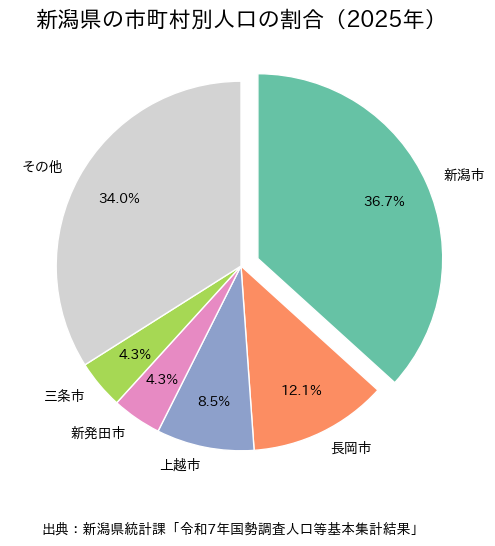

In [2]:
df_city = pd.read_excel('DSA2026_kadai2_模範解答.xlsx', sheet_name='問1_円グラフ')

colors = list(plt.get_cmap('Set2').colors[:5]) + ['lightgray']
shift = [0.1, 0, 0, 0, 0, 0]  # 新潟市だけ切り出す

plt.figure(figsize=(6, 6))
plt.pie(df_city['人口'], labels=df_city['市町村'], colors=colors, explode=shift,
        startangle=90, counterclock=False,
        autopct='%.1f%%', pctdistance=0.75,
        wedgeprops={'edgecolor': 'w'})
plt.title('新潟県の市町村別人口の割合（2025年）', fontsize=16)
plt.figtext(0.5, 0.05, '出典：新潟県統計課「令和7年国勢調査人口等基本集計結果」', ha='center')
plt.savefig('kadai2_q1.png', transparent=True, bbox_inches='tight')
plt.show()

## 問2 両 y 軸グラフ

- データ：新潟県の人口と世帯数（1995〜2025年、5年ごと）
- 出典：新潟県統計課「令和7年国勢調査人口等基本集計結果 新潟県の人口と世帯（確定値）」の表（人口の推移、世帯数の推移）
  - ページ：https://www.pref.niigata.lg.jp/site/tokei/2025kokucho-kakuhou.html
  - PDF：https://www.pref.niigata.lg.jp/uploaded/attachment/512836.pdf
- 人口（人）と世帯数（世帯）は単位が違うので、左右に y 軸を分ける。数が大きいので、どちらも「万」で表す

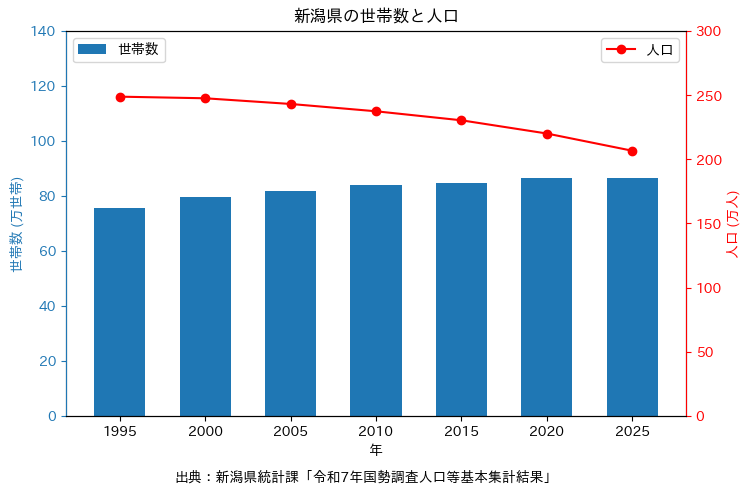

In [3]:
df_pop = pd.read_excel('DSA2026_kadai2_模範解答.xlsx', sheet_name='問2_両y軸')

plt.figure(figsize=(8, 5))

plt.bar(df_pop['年'], df_pop['世帯数'] / 10000, width=3, color='tab:blue', label='世帯数')
plt.ylabel('世帯数 (万世帯)', color='tab:blue')
plt.ylim(0, 140)
plt.tick_params(axis='y', colors='tab:blue')
plt.xlabel('年')
plt.xticks(df_pop['年'])
plt.title('新潟県の世帯数と人口')
plt.legend(loc='upper left')

plt.twinx()
plt.plot(df_pop['年'], df_pop['人口'] / 10000, color='r', marker='o', label='人口')
plt.ylabel('人口 (万人)', color='r')
plt.ylim(0, 300)
plt.tick_params(axis='y', colors='r')
plt.gca().spines['right'].set_color('r')
plt.gca().spines['left'].set_color('tab:blue')
plt.legend(loc='upper right')

plt.figtext(0.5, -0.02, '出典：新潟県統計課「令和7年国勢調査人口等基本集計結果」', ha='center')
plt.savefig('kadai2_q2.png', transparent=True, bbox_inches='tight')
plt.show()

## 問3 指数化グラフ

- 問2と同じデータを、1995年を 100 にして指数化する（それぞれの年の値 ÷ 1995年の値 × 100）
- 1本の y 軸で、世帯数と人口の増え方・減り方を比べられる

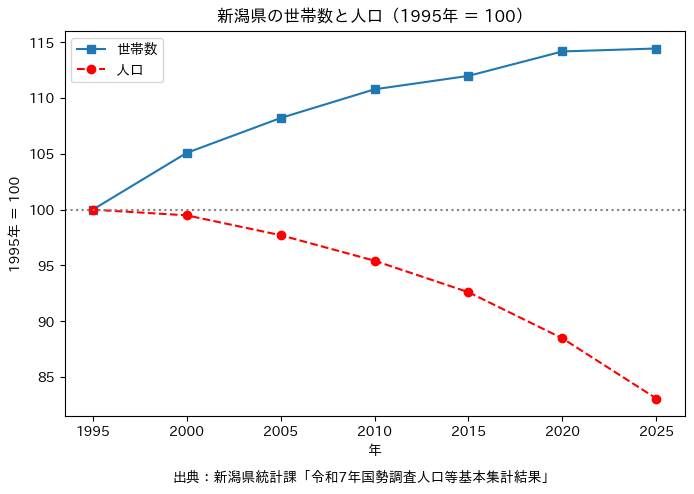

In [4]:
idx_house = df_pop['世帯数'] / df_pop['世帯数'][0] * 100
idx_pop = df_pop['人口'] / df_pop['人口'][0] * 100

plt.figure(figsize=(8, 5))
plt.plot(df_pop['年'], idx_house, color='tab:blue', marker='s', label='世帯数')
plt.plot(df_pop['年'], idx_pop, color='r', marker='o', linestyle='--', label='人口')
plt.axhline(100, color='gray', linestyle=':')
plt.xlabel('年')
plt.xticks(df_pop['年'])
plt.ylabel('1995年 ＝ 100')
plt.title('新潟県の世帯数と人口（1995年 ＝ 100）')
plt.legend()
plt.figtext(0.5, -0.02, '出典：新潟県統計課「令和7年国勢調査人口等基本集計結果」', ha='center')
plt.savefig('kadai2_q3.png', transparent=True, bbox_inches='tight')
plt.show()

## 問4 エラーバー付きグラフ

- データ：`DSA2026_kadai2.xlsx` のシート `問4_身長`（5〜17歳の男子・女子の身長の平均と標準偏差）。ここでは身長を選ぶ
- 出典：文部科学省「学校保健統計調査」（令和7年度）
  - https://www.mext.go.jp/b_menu/toukei/chousa05/hoken/1268826.htm
- 横軸は、文字の列 `年齢`（`'5歳'`〜`'17歳'`）を使う。目盛りに「5歳」「6歳」…がそのまま出るので、`plt.xticks` はいらない
- 横軸が文字のときは、`plt.text` の x は左から 0, 1, 2, … の番号になる（5歳が 0、17歳が 12）

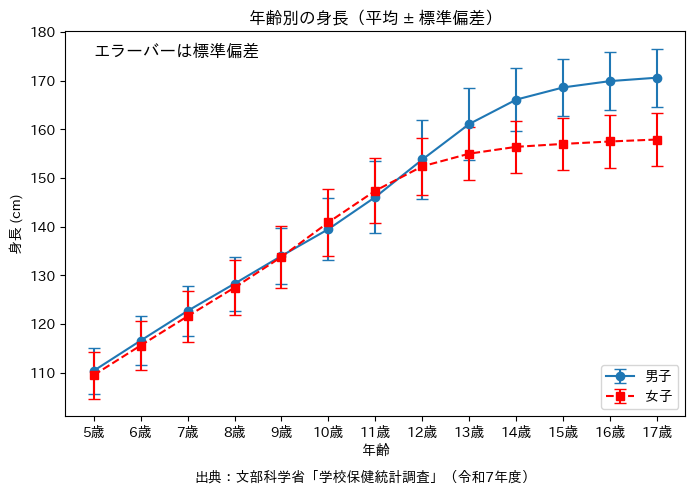

In [5]:
df = pd.read_excel('DSA2026_kadai2_模範解答.xlsx', sheet_name='問4_身長')

plt.figure(figsize=(8, 5))
plt.errorbar(df['年齢'], df['男子_mean(cm)'], yerr=df['男子_std(cm)'],
             fmt='o-', color='tab:blue', capsize=4, label='男子')
plt.errorbar(df['年齢'], df['女子_mean(cm)'], yerr=df['女子_std(cm)'],
             fmt='s--', color='r', capsize=4, label='女子')
plt.text(0, 175, 'エラーバーは標準偏差', fontsize=12)  # x は番号（0 が 5歳）
plt.xlabel('年齢')
plt.ylabel('身長 (cm)')
plt.title('年齢別の身長（平均 ± 標準偏差）')
plt.legend(loc='lower right')
plt.figtext(0.5, -0.02, '出典：文部科学省「学校保健統計調査」（令和7年度）', ha='center')
plt.savefig('kadai2_q4.png', transparent=True, bbox_inches='tight')
plt.show()

## 任意課題 問4を数の目盛りで描く

- 横軸に、数の列 `年齢(歳)`（5〜17）を使う。何もしないと目盛りが 6, 8, 10, … と飛ぶので、`plt.xticks(range(5, 18))` で1歳ずつ出す
- 横軸が数のときは、`plt.text` の x は年齢の値になる（5 なら 5歳の位置）

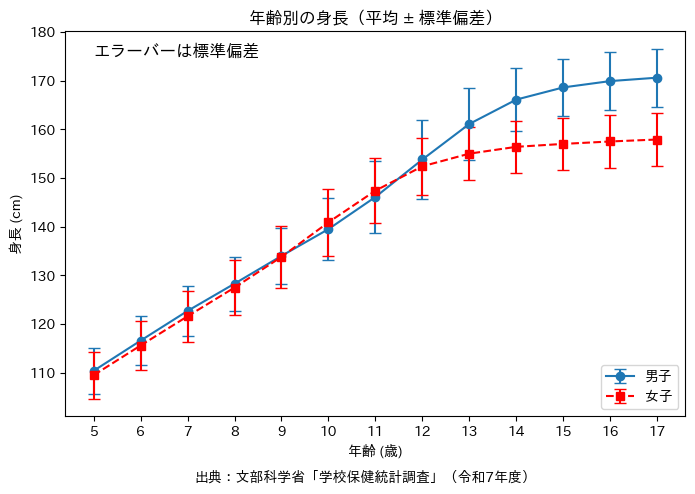

In [6]:
plt.figure(figsize=(8, 5))
plt.errorbar(df['年齢(歳)'], df['男子_mean(cm)'], yerr=df['男子_std(cm)'],
             fmt='o-', color='tab:blue', capsize=4, label='男子')
plt.errorbar(df['年齢(歳)'], df['女子_mean(cm)'], yerr=df['女子_std(cm)'],
             fmt='s--', color='r', capsize=4, label='女子')
plt.text(5, 175, 'エラーバーは標準偏差', fontsize=12)  # x は年齢の値
plt.xlabel('年齢 (歳)')
plt.xticks(range(5, 18))
plt.ylabel('身長 (cm)')
plt.title('年齢別の身長（平均 ± 標準偏差）')
plt.legend(loc='lower right')
plt.figtext(0.5, -0.02, '出典：文部科学省「学校保健統計調査」（令和7年度）', ha='center')
plt.savefig('kadai2_qopt.png', transparent=True, bbox_inches='tight')
plt.show()